# 03 · ANN (Artificial Neural Network) Model

**Goal:** build a simple baseline: a plain fully-connected network that treats each image as one long list of numbers. In notebook 04 we compare it with a CNN, which is designed for images, to see how much the design matters.

## 1  ANN Architecture Design

An ANN is a stack of layers, and each layer holds neurons that combine their inputs using learned weights. We use three hidden layers that get smaller (256 → 128 → 64 neurons), so the network gradually squeezes the image down to the most useful information. The last layer has 4 neurons, one per class.

In [ ]:
import numpy as np
import tensorflow as tf 
from tensorflow.keras import layers, models

In [ ]:
IMG_SIZE = (224, 224)
CHANNELS = 1
INPUT_FEATURES = 224 * 224 * CHANNELS
HIDDEN_UNITS = [256, 128, 64]
NUM_CLASSES = 4

print("Input features:", INPUT_FEATURES)
print("Hidden layers:", HIDDEN_UNITS)
print("Output classes:", NUM_CLASSES)

Input features: 50176
Hidden layers: [256, 128, 64]
Output classes: 4


## 2 Flattening MRI images

In [3]:
from pathlib import Path

PROJECT_DIR = Path("..")
TRAIN_DIR = PROJECT_DIR / "dataset" / "Training"
TEST_DIR = PROJECT_DIR / "dataset" / "Testing"

sample_path = next((TRAIN_DIR / "glioma").glob("*.jpg"))
sample_img = tf.keras.utils.load_img(sample_path,target_size=IMG_SIZE,color_mode="grayscale")
sample_array = tf.keras.utils.img_to_array(sample_img)

print("Original shape:", sample_array.shape)

Original shape: (224, 224, 1)


In [4]:
flattened_image = sample_array.flatten()

print("Original shape:", sample_array.shape)
print("Flattened shape:", flattened_image.shape)
print("Total features:", flattened_image.size)

Original shape: (224, 224, 1)
Flattened shape: (50176,)
Total features: 50176


## 3 Dense layers and activation functions

In [5]:
ann_model = models.Sequential([layers.Input(shape=(INPUT_FEATURES,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")])
    
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,886,724 (49.16 MB)

 Trainable params: 12,886,724 (49.16 MB)

 Non-trainable params: 0 (0.00 B)

## 4 Model compiling

In [6]:
ann_model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]) 

## 5 Model Training

In [7]:
from sklearn.model_selection import train_test_split

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
class_names = sorted(folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir())

class_to_label = {name: index for index, name in enumerate(class_names)}

In [8]:
train_paths = []
train_labels = []

for class_name in class_names:
    for path in (TRAIN_DIR / class_name).rglob("*"):
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            train_paths.append(str(path))
            train_labels.append(class_to_label[class_name])

test_paths = []
test_labels = []

for class_name in class_names:
    for path in (TEST_DIR / class_name).rglob("*"):
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            test_paths.append(str(path))
            test_labels.append(class_to_label[class_name])

train_paths = np.array(train_paths)
train_labels = np.array(train_labels)

test_paths = np.array(test_paths)
test_labels = np.array(test_labels)

X_train, X_val, y_train, y_val = train_test_split(train_paths,train_labels,test_size=0.20,random_state=42,stratify=train_labels)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(test_paths))

Training: 4480
Validation: 1120
Testing: 1600


In [9]:
def preprocess_image(image_path, label):
    image = tf.io.read_file(image_path) # image is read 
    image = tf.io.decode_image(image,channels=1,expand_animations=False) # image is decoded to pixels 
    image.set_shape([None, None, 1]) 
    image = tf.image.resize(image, IMG_SIZE) # reshaping image to 224 ,224
    image = tf.cast(image, tf.float32) / 255.0 # normalise the image 
    image = tf.reshape(image, [INPUT_FEATURES]) # Flattens the image into 50,176 features.

    return image, label

In [ ]:
BATCH_SIZE = 16

def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image,num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        dataset = dataset.shuffle(buffer_size=len(paths),seed=42)

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_dataset = create_dataset(X_train, y_train, training=True)
val_dataset = create_dataset(X_val, y_val)

In [11]:
history = ann_model.fit(train_dataset,validation_data=val_dataset,epochs=10)

Epoch 1/10


d:\MRI-Brain-Tumor-Classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


280/280 ━━━━━━━━━━━━━━━━━━━━ 43s 115ms/step - accuracy: 0.5855 - loss: 1.1490 - val_accuracy: 0.6607 - val_loss: 0.8468
Epoch 2/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 81s 284ms/step - accuracy: 0.7098 - loss: 0.7133 - val_accuracy: 0.7366 - val_loss: 0.7073
Epoch 3/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - accuracy: 0.7685 - loss: 0.5842 - val_accuracy: 0.7437 - val_loss: 0.6698
Epoch 4/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 39s 106ms/step - accuracy: 0.8121 - loss: 0.4871 - val_accuracy: 0.7839 - val_loss: 0.6216
Epoch 5/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 36s 122ms/step - accuracy: 0.8212 - loss: 0.4558 - val_accuracy: 0.7679 - val_loss: 0.7493
Epoch 6/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.8328 - loss: 0.4219 - val_accuracy: 0.7866 - val_loss: 0.6049
Epoch 7/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 41s 144ms/step - accuracy: 0.8696 - loss: 0.3314 - val_accuracy: 0.7652 - val_loss: 0.7405
Epoch 8/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - accuracy: 0.8922 - loss: 0.2901 - val

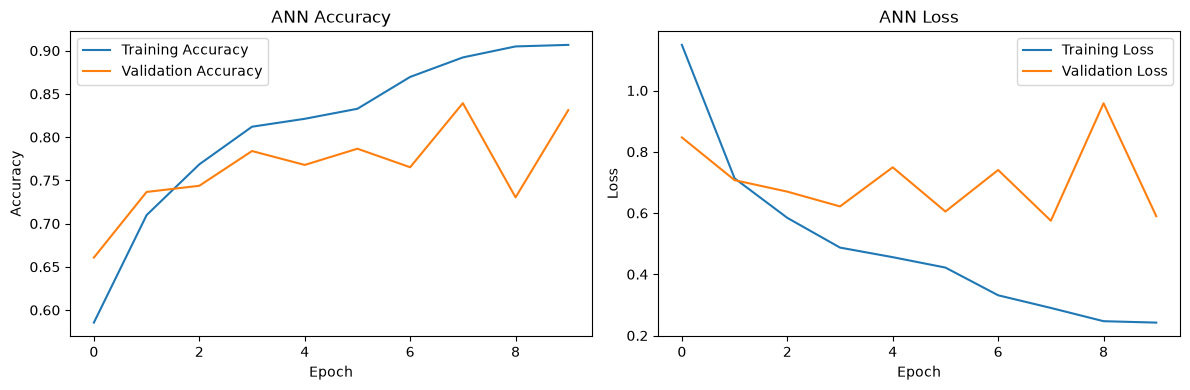

In [20]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig('../images/ann_training_results.png',dpi=300,bbox_inches="tight")
plt.show()
plt.show()

In [14]:
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

ann_model.save(MODEL_DIR / "ann_brain_tumor.keras")

print("ANN model saved successfully!")

ANN model saved successfully!


In [15]:
import json

with open(MODEL_DIR / "ann_training_history.json", "w") as f:
    json.dump(history.history, f)

print("Training history saved!")

Training history saved!


## Summary

| Item | Value |
|---|---|
| Input | 224 x 224 grayscale image, flattened to 50,176 numbers |
| Architecture | Dense 256 → 128 → 64 → 4 (ReLU, softmax output) |
| Parameters | about 12.9 million |
| Training | Adam, sparse categorical crossentropy, batch size 16, 10 epochs |
| Saved files | `models/ann_brain_tumor.keras`, `models/ann_training_history.json` |

**Figure saved for the README:** `ann_training_results.png`

**Next:** `04_cnn_model.ipynb`